# 01 · Análise exploratória — bilhetagem ViaCard

Base: lote sintético **v4.4** (2.500 cartões, ~5 anos cada), já na camada **silver**
(`python -m src.pipeline`). Perguntas:

1. Como é o uso *normal* (volume, horário, linhas)?
2. A qualidade dos dados sustenta a modelagem?
3. Onde os eventos de fraude aparecem — e o que os diferencia do uso normal?

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if (Path.cwd().parent / "mlops").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SILVER = ROOT / "data/processed/silver"
GOLD = ROOT / "data/processed/gold"
REPORTS = ROOT / "mlops/reports"

In [2]:
cols = ["card_id", "event_ts", "tipo", "status_emb", "operador_display", "codigo_linha", "tipo_linha",
        "vd", "saldo", "is_debito", "is_recarga", "hora", "dia_semana", "ano_mes", "descricao"]
tx = pd.read_parquet(SILVER / "transactions.parquet", columns=cols)
labels = pd.read_parquet(SILVER / "labels_cartao.parquet")
eventos_fraude = pd.read_parquet(SILVER / "labels_eventos.parquet")
print(f"{len(tx):,} transações | {tx.card_id.nunique():,} cartões | {tx.event_ts.min():%Y-%m} a {tx.event_ts.max():%Y-%m}")
labels["classe"].value_counts().to_frame("cartões")

7,772,517 transações | 2,500 cartões | 2020-01 a 2025-12


,cartões
classe,
Regular,1881
Fraudulento,556
Suspeito,63


## Qualidade da silver
As checagens bloqueantes rodam no pipeline; aqui só conferimos o relatório.

In [3]:
rel = json.loads((SILVER / "quality_report.json").read_text(encoding="utf-8"))
print({k: rel[k] for k in ("total", "aprovadas", "erros", "alertas")})
pd.DataFrame(rel["checks"])[["tabela", "nome", "ok", "observado", "esperado", "severidade"]]

{'total': 20, 'aprovadas': 20, 'erros': 0, 'alertas': 0}


,tabela,nome,ok,observado,esperado,severidade
0,silver.transactions,card_id_nao_nulo,True,0,0,erro
1,silver.transactions,event_ts_nao_nulo,True,0,0,erro
2,silver.transactions,tipo_no_dominio,True,0,0,erro
3,silver.transactions,status_no_dominio,True,0,0,erro
4,silver.transactions,vd_positivo,True,0,0,erro
5,silver.transactions,carteiras_nao_negativas,True,0,0,erro
6,silver.transactions,saldo_ate_teto,True,0,0,erro
7,silver.transactions,dc_coerente,True,0,0,erro
8,silver.transactions,descricao_embarque_parseada,True,0,0,erro
9,silver.transactions,descricao_recarga_parseada,True,0,0,erro


## Volume e receita por operadora

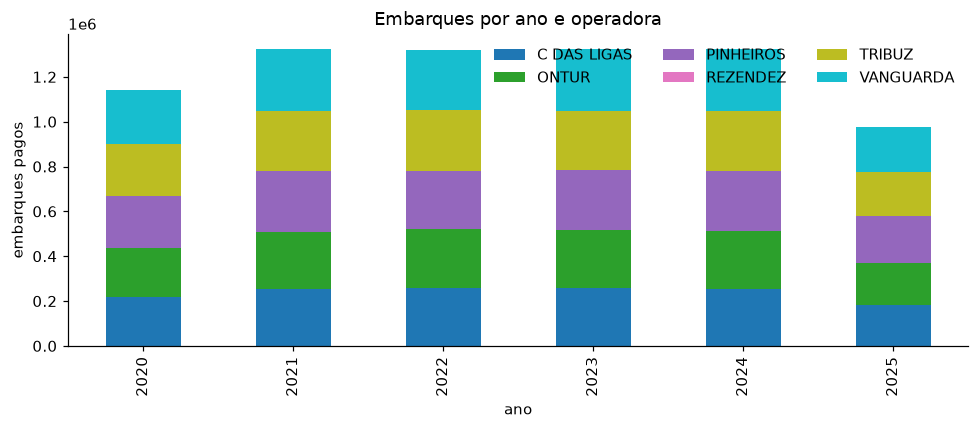

In [4]:
emb = tx[tx.is_debito]
anual = emb.assign(ano=emb.event_ts.dt.year).pivot_table(index="ano", columns="operador_display",
                                                          values="vd", aggfunc="count", fill_value=0)
ax = anual.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="tab10")
ax.set_ylabel("embarques pagos"); ax.set_title("Embarques por ano e operadora"); ax.legend(frameon=False, ncol=3)
plt.tight_layout()

## Quando as pessoas embarcam?
Padrão de rotina de trabalho: picos às 6-7h e 17-18h; fim de semana bem menor.

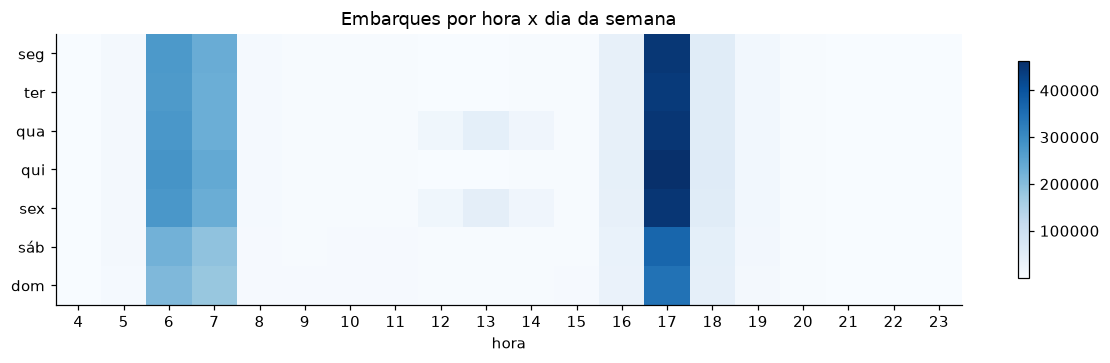

In [5]:
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
calor = emb.pivot_table(index="dia_semana", columns="hora", values="vd", aggfunc="count", fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(calor, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), dias); ax.set_xticks(range(calor.shape[1]), calor.columns)
ax.set_xlabel("hora"); ax.set_title("Embarques por hora x dia da semana")
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout()

## Linhas mais usadas

In [6]:
dim_linha = pd.read_parquet(SILVER / "dim_linha.parquet")
top = (emb.groupby(["operador_display", "codigo_linha"]).size().rename("embarques").reset_index()
       .merge(dim_linha[["operador_display", "codigo_linha", "trajeto", "tipo_linha", "tarifa_tabela"]])
       .sort_values("embarques", ascending=False).head(10))
top.assign(pct=lambda d: (100 * d.embarques / len(emb)).round(2))

,operador_display,codigo_linha,embarques,trajeto,tipo_linha,tarifa_tabela,pct
114,PINHEIROS,PI200,401720,Circular Residencial Morada do Bosque,MUNICIPAL,5.9,5.42
115,PINHEIROS,PI201,386750,Conforto x Aero,MUNICIPAL,5.9,5.22
117,PINHEIROS,PI203,371232,Três Poços x Ponte Alta (Radial Leste),MUNICIPAL,5.9,5.01
116,PINHEIROS,PI202,347833,Nova Primavera x Ponte Alta (Municipal),MUNICIPAL,5.9,4.69
2,C DAS LIGAS,302,107469,Cacaria x Pirai (Mun Pirai),MUNICIPAL,6.0,1.45
3,C DAS LIGAS,303,93148,Cacaria x Seropedica,MUNICIPAL,5.8,1.26
9,C DAS LIGAS,309,92443,Pirai x Sarole/Cruzeiro (Mun Pirai),MUNICIPAL,6.0,1.25
12,C DAS LIGAS,312,91753,Ribeirao da Lajes x Pirai (Mun Pirai),MUNICIPAL,6.0,1.24
15,C DAS LIGAS,315,82381,Roma l x Cajueiro,MUNICIPAL,5.9,1.11
16,C DAS LIGAS,316,79321,Santanesia x Pirai (Mun Pirai),MUNICIPAL,6.0,1.07


## Recargas

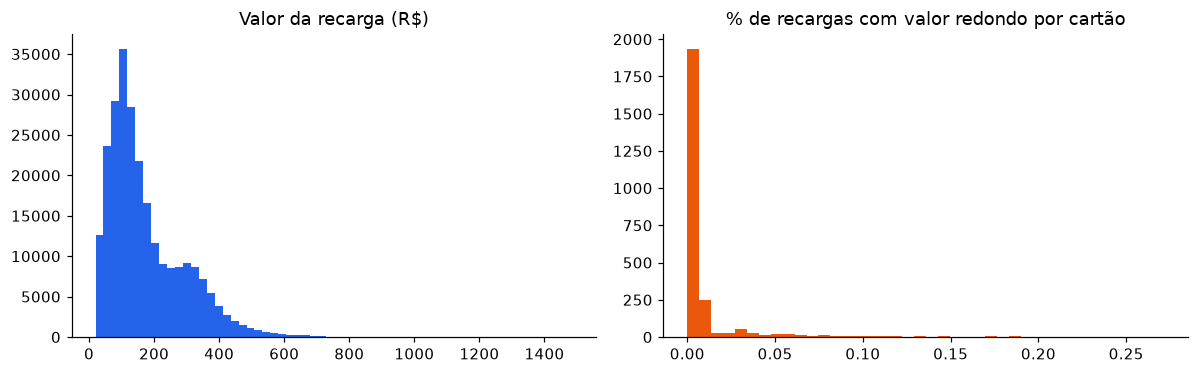

In [7]:
rec = tx[tx.is_recarga]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(rec.vd, bins=60, color="#2563EB"); axes[0].set_title("Valor da recarga (R$)")
redondas = (rec.vd % 10 == 0).groupby(rec.card_id).mean()
axes[1].hist(redondas, bins=40, color="#EA580C"); axes[1].set_title("% de recargas com valor redondo por cartão")
plt.tight_layout()

## Onde está a fraude?

`labels_eventos` marca **cada evento** fraudulento (ground truth fino do gerador v4.4). Comparamos
esses eventos com o uso legítimo — é daqui que saem as hipóteses das features.

In [8]:
eventos_fraude["fraude"].value_counts().to_frame("eventos")

,eventos
fraude,
Desvio de finalidade,14172
Uso de gratuidade associado ao VT,12439
Empréstimo do cartão,10998
Uso em licença,10800
Venda de créditos,10638
Uso em férias,9844
Clonagem,9119
Replay,8547
Uso offline,7494


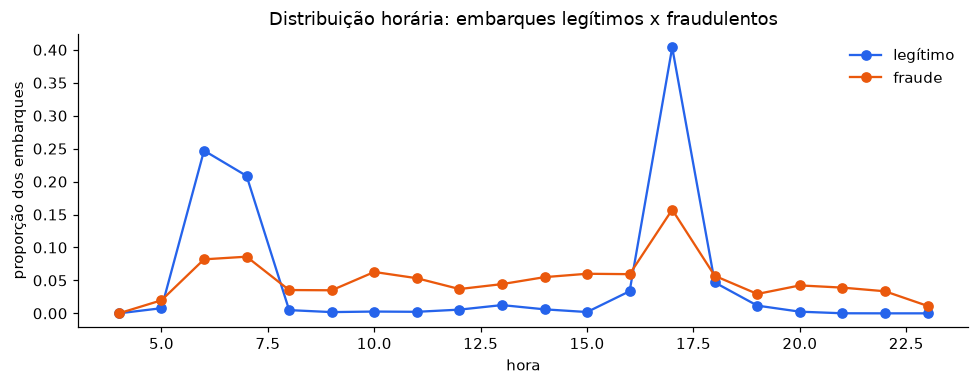

In [9]:
chave = ["card_id", "event_ts", "descricao"]
marcado = tx.merge(eventos_fraude[chave + ["fraude"]].drop_duplicates(chave), on=chave, how="left")
usados = marcado[marcado.tipo == "USADO"]
comp = usados.assign(grupo=np.where(usados.fraude.isna(), "legítimo", "fraude"))
fig, ax = plt.subplots(figsize=(9, 3.6))
for g, cor in (("legítimo", "#2563EB"), ("fraude", "#EA580C")):
    h = comp.loc[comp.grupo == g, "hora"].value_counts(normalize=True).sort_index()
    ax.plot(h.index, h.values, marker="o", color=cor, label=g)
ax.set_xlabel("hora"); ax.set_ylabel("proporção dos embarques"); ax.legend(frameon=False)
ax.set_title("Distribuição horária: embarques legítimos x fraudulentos"); plt.tight_layout()

In [10]:
perfil = (usados.dropna(subset=["fraude"]).groupby("fraude")
          .agg(eventos=("vd", "size"), hora_mediana=("hora", "median"),
               pct_fim_semana=("dia_semana", lambda d: (d >= 5).mean()),
               pct_intermunicipal=("tipo_linha", lambda t: (t == "INTERMUNICIPAL").mean()),
               pct_status_normal=("status_emb", lambda s: (s == "NORMAL").mean()))
          .round(3).sort_values("eventos", ascending=False))
perfil

,eventos,hora_mediana,pct_fim_semana,pct_intermunicipal,pct_status_normal
fraude,,,,,
Desvio de finalidade,14172,21.0,0.290,0.000,0.980
Uso de gratuidade associado ao VT,12439,15.0,0.228,0.000,0.988
Empréstimo do cartão,10998,11.0,0.410,0.000,0.972
Uso em licença,10800,12.0,0.295,0.000,0.989
Venda de créditos,10638,15.0,0.288,0.000,0.946
Uso em férias,9844,14.0,0.284,1.000,0.879
Clonagem,9119,14.0,0.227,0.000,0.636
Replay,8548,14.0,0.265,0.000,0.989
Uso offline,7494,16.0,0.245,0.001,1.000


### Achados

- A rotina domina: 2 embarques/dia, picos de manhã e fim de tarde, uma linha principal por época de emprego.
- Fraude é **rara e episódica**: poucos % dos embarques de um fraudador, concentrados em janelas de semanas.
  Médias de 5 anos diluem o sinal → features de **pico mensal** contra o próprio histórico (notebook 02).
- Cada tipo tem uma assinatura distinta (meio do dia na licença, intermunicipal nas férias, noite no desvio,
  valor redondo na recarga clandestina) — nenhuma feature isolada pega todos.